In [12]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/concrete-strength-regression/sample_submission.csv
/kaggle/input/competitions/concrete-strength-regression/train.csv
/kaggle/input/competitions/concrete-strength-regression/test.csv


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import os
import joblib

# =================================================================
# 1. "ULTRACLEAN" FEATURE ENGINEERING
# =================================================================
def expert_features(df):
    df = df.copy()
    eps = 1e-6
    df['w_b_ratio'] = df['water'] / (df['cement'] + df['slag'] + df['flyash'] + eps)
    df['log_age'] = np.log1p(df['age'])
    df['cement_age'] = df['cement'] * df['log_age']
    df['binder_richness'] = (df['cement'] + df['slag'] + df['flyash']) / (df['fineaggregate'] + df['coarseaggregate'] + eps)
    
    cols_to_drop = ['age', 'Row ID']
    return df.drop(columns=cols_to_drop, errors='ignore')

# Data loading
train_raw = pd.read_csv("/kaggle/input/competitions/concrete-strength-regression/train.csv")
test_raw = pd.read_csv("/kaggle/input/competitions/concrete-strength-regression/test.csv")

Target = 'csMPa'
X = expert_features(train_raw.drop(columns=[Target]))
# Kept as 2D DataFrame [[Target]] so PowerTransformer doesn't raise ValueError
y = train_raw[[Target]]
X_test_final = expert_features(test_raw)

# 1. Create output directory to store folds and scalers
output_dir = "/kaggle/working/folds"
os.makedirs(output_dir, exist_ok=True)

# Retrieve feature and target column names
feature_columns = list(X.columns)
target_column = Target

print("2. Generating and exporting 10 folds (sub-datasets)...")
print("-" * 70)
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# 2. Iterate through folds
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    
    X_train_f, X_val_f = X.iloc[train_idx], X.iloc[val_idx]
    y_train_f, y_val_f = y.iloc[train_idx], y.iloc[val_idx]

    # =================================================================
    # 2. DOUBLE POWER TRANSFORM (Yeo-Johnson)
    # =================================================================
    pt_x = PowerTransformer(method='yeo-johnson').fit(X_train_f)
    pt_y = PowerTransformer(method='yeo-johnson').fit(y_train_f)

    # Save X and y scalers
    scaler_features_path = os.path.join(output_dir, f"scale_features_{fold}.joblib")
    scaler_target_path = os.path.join(output_dir, f"scale_target_{fold}.joblib")
    
    joblib.dump(pt_x, scaler_features_path)
    joblib.dump(pt_y, scaler_target_path)

    X_scaled = pt_x.transform(X_train_f)
    y_scaled = pt_y.transform(y_train_f)
    X_val_scaled = pt_x.transform(X_val_f)
    y_val_scaled = pt_y.transform(y_val_f)
    X_test_scaled = pt_x.transform(X_test_final)
    
    # Reconstruct Pandas DataFrames (flatten y to ensure a 1D column)
    df_train = pd.DataFrame(X_scaled, columns=feature_columns)
    df_train[target_column] = y_scaled.flatten()
    
    df_val = pd.DataFrame(X_val_scaled, columns=feature_columns)
    df_val[target_column] = y_val_scaled.flatten()

    df_test = pd.DataFrame(X_test_scaled, columns=feature_columns)
    
    # Define save paths
    train_filename = os.path.join(output_dir, f"train_fold_{fold}_scaled.csv")
    val_filename = os.path.join(output_dir, f"val_fold_{fold}_scaled.csv")
    test_filename = os.path.join(output_dir, f"test_fold_{fold}_scaled.csv")
    
    # Export to CSV (without index)
    df_train.to_csv(train_filename, index=False)
    df_val.to_csv(val_filename, index=False)
    df_test.to_csv(test_filename, index=False)
    
    print(f"Fold {fold:02d} exported -> Train: {df_train.shape} | Val: {df_val.shape} | Test: {df_test.shape}")

print("-" * 70)
print(f"Process completed. Files are saved in: {output_dir}")


2. Generating and exporting 10 folds (sub-datasets)...
----------------------------------------------------------------------
Fold 00 exported -> Train: (648, 12) | Val: (73, 12) | Test: (309, 11)
Fold 01 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 02 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 03 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 04 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 05 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 06 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 07 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 08 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
Fold 09 exported -> Train: (649, 12) | Val: (72, 12) | Test: (309, 11)
----------------------------------------------------------------------
Process completed. Files are saved in: /kaggle/working/folds


Device sélectionné pour XGBoost : CPU

PHASE 1 : GÉNÉRATION DU 10-FOLD DE TUNING (ZERO-LEAKAGE, SEED 2024)
10 plis de tuning pré-transformés avec succès (90% données d'entraînement préservées).
--- 1. VERSIONS DES PACKAGES ---
NumPy: 2.1.3 | Sklearn: 1.6.1 | XGBoost: 3.4.1 | Scipy: 1.16.3

--- 2. EMPREINTE DES DONNÉES TUNING (Fold 0) ---
Somme X_train fold 0 : -0.000000
Somme y_train fold 0 : -0.000000

RECHERCHE HYPERPARAMÈTRES : 25 essais × 10 plis de tuning


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/

Essai 01/25 | Tuning MSE = 23.0893 ± 7.4728 MPa²


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/

Essai 02/25 | Tuning MSE = 25.2661 ± 7.1717 MPa²


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/

... (61 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(


Fold 08 |      3.99 |        24.4649 |   0.9135


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(


Fold 09 |      3.23 |        14.2039 |   0.9540

RÉSULTATS FINAUX STRICTS (OOF - MPa)
MSE GLOBAL (OOF)  : 17.1356 MPa²
RMSE GLOBAL (OOF) : 4.1395 MPa
MAE GLOBAL (OOF)  : 2.8616 MPa
R² GLOBAL (OOF)   : 0.9420
Moyenne des MSEs  : 17.1428 ± 7.9631 MPa²


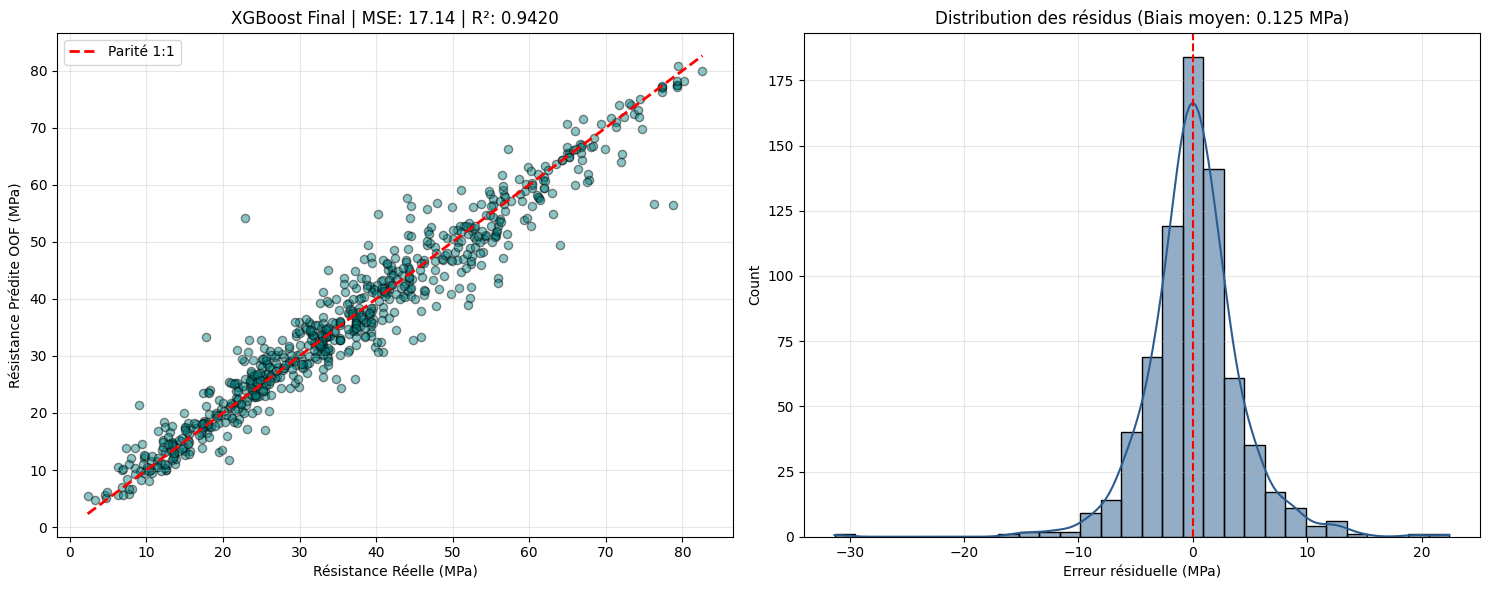


Fichier 'submission.csv' généré avec succès (309 lignes).


In [14]:

import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# =================================================================
# 1. CONFIGURATION ET CHARGEMENT DES DONNÉES BRUTES
# =================================================================
param = 'csMPa'
N_FOLDS = 10
N_TRIALS = 25
MAX_ESTIMATORS = 4000
EARLY_STOPPING = 100

def find_data_file(filename):
    search_paths = [
        f"/kaggle/input/competitions/concrete-strength-regression/{filename}"
    ]
    for path in search_paths:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"Fichier {filename} introuvable.")

train_path = find_data_file("train.csv")
test_path = find_data_file("test.csv")

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)

# Feature engineering physique expert
def expert_features(df):
    df = df.copy()
    eps = 1e-6
    df['w_b_ratio'] = df['water'] / (df['cement'] + df['slag'] + df['flyash'] + eps)
    df['log_age'] = np.log1p(df['age'])
    df['cement_age'] = df['cement'] * df['log_age']
    df['binder_richness'] = (df['cement'] + df['slag'] + df['flyash']) / (df['fineaggregate'] + df['coarseaggregate'] + eps)
    
    cols_to_drop = ['age', 'Row ID']
    return df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')

X = expert_features(train_raw.drop(columns=['csMPa'])).reset_index(drop=True)
y = train_raw[['csMPa']].reset_index(drop=True)
X_test_final = expert_features(test_raw).reset_index(drop=True)

# Détection du matériel (GPU/CPU)
try:
    import torch
    device_choice = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    device_choice = "cpu"

print(f"Device sélectionné pour XGBoost : {device_choice.upper()}")

# =================================================================
# 2. PHASE 1 : PRÉPARATION DU JEU DE TUNING (10-FOLD SÉPARÉ, SEED 2024)
# =================================================================
# On utilise une graine différente (seed 2024) avec 90% train / 10% val à chaque pli.
# Aucune perte de données, et les plis de l'ANN (seed 42) restent 100% aveugles.
print("\n" + "=" * 75)
print("PHASE 1 : GÉNÉRATION DU 10-FOLD DE TUNING (ZERO-LEAKAGE, SEED 2024)")
print("=" * 75)

kf_tune = KFold(n_splits=N_FOLDS, shuffle=True, random_state=2024)
tuning_folds = []

for fold, (t_idx, v_idx) in enumerate(kf_tune.split(X, y)):
    X_tr_raw, y_tr_raw = X.iloc[t_idx].copy(), y.iloc[t_idx].copy()
    X_va_raw, y_va_raw = X.iloc[v_idx].copy(), y.iloc[v_idx].copy()

    # Yeo-Johnson ajusté UNIQUEMENT sur le Train de ce pli de tuning
    pt_x_tune = PowerTransformer(method='yeo-johnson')
    pt_y_tune = PowerTransformer(method='yeo-johnson')

    X_tr_scaled = pt_x_tune.fit_transform(X_tr_raw)
    y_tr_scaled = pt_y_tune.fit_transform(y_tr_raw).flatten()

    X_va_scaled = pt_x_tune.transform(X_va_raw)
    y_va_scaled = pt_y_tune.transform(y_va_raw).flatten()

    y_va_real_mpa = y_va_raw.values.flatten()

    tuning_folds.append({
        "X_train": X_tr_scaled,
        "y_train": y_tr_scaled,
        "X_val": X_va_scaled,
        "y_val": y_va_scaled,
        "y_val_real_mpa": y_va_real_mpa,
        "pt_y": pt_y_tune
    })

print(f"{len(tuning_folds)} plis de tuning pré-transformés avec succès (90% données d'entraînement préservées).")

# =================================================================
# 3. RECHERCHE ALÉATOIRE DES HYPERPARAMÈTRES (SUR TUNING FOLDS)
# =================================================================

import scipy, sklearn, xgboost

print("--- 1. VERSIONS DES PACKAGES ---")
print(
    f"NumPy: {np.__version__} | Sklearn: {sklearn.__version__} | XGBoost: {xgboost.__version__} | Scipy: {scipy.__version__}"
)

print("\n--- 2. EMPREINTE DES DONNÉES TUNING (Fold 0) ---")
print(f"Somme X_train fold 0 : {tuning_folds[0]['X_train'].sum():.6f}")
print(f"Somme y_train fold 0 : {tuning_folds[0]['y_train'].sum():.6f}")


rng = np.random.default_rng(42)

def sample_params(rng):
    return {
        "n_estimators": MAX_ESTIMATORS,
        "learning_rate": float(rng.choice([0.005, 0.01, 0.02, 0.03, 0.05, 0.08])),
        "max_depth": int(rng.choice([3, 4, 5, 6, 7])),
        "min_child_weight": float(rng.choice([1, 2, 3, 5, 7])),
        "subsample": float(rng.choice([0.65, 0.75, 0.85, 0.95])),
        "colsample_bytree": float(rng.choice([0.6, 0.7, 0.8, 0.9])),
        "gamma": float(rng.choice([0, 0.01, 0.05, 0.1, 0.2])),
        "reg_alpha": float(rng.choice([0, 0.01, 0.1, 1.0, 5.0])),
        "reg_lambda": float(rng.choice([0.5, 1.0, 2.0, 5.0, 10.0]))
    }

best_params = None
best_tune_mse = np.inf
search_results = []

print("\n" + "=" * 75)
print(f"RECHERCHE HYPERPARAMÈTRES : {N_TRIALS} essais × 10 plis de tuning")
print("=" * 75)

for trial in range(N_TRIALS):
    params = sample_params(rng)
    trial_mses = []

    for fold_data in tuning_folds:
        model = XGBRegressor(
            **params,
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=42,
            early_stopping_rounds=EARLY_STOPPING,
            tree_method="hist",
            device=device_choice,
            n_jobs=-1
        )

        model.fit(
            fold_data["X_train"],
            fold_data["y_train"],
            eval_set=[(fold_data["X_val"], fold_data["y_val"])],
            verbose=False
        )

        pred_scaled = model.predict(fold_data["X_val"])
        pred_mpa = fold_data["pt_y"].inverse_transform(pred_scaled.reshape(-1, 1)).flatten()

        trial_mses.append(mean_squared_error(fold_data["y_val_real_mpa"], pred_mpa))

    mean_mse = float(np.mean(trial_mses))
    std_mse = float(np.std(trial_mses, ddof=1))

    search_results.append({
        "trial": trial + 1,
        "mean_tune_mse": mean_mse,
        "std_tune_mse": std_mse,
        **params
    })

    print(f"Essai {trial + 1:02d}/{N_TRIALS} | Tuning MSE = {mean_mse:.4f} ± {std_mse:.4f} MPa²")

    if mean_mse < best_tune_mse:
        best_tune_mse = mean_mse
        best_params = params.copy()

print("\n" + "-" * 60)
print(f"MEILLEURS HYPERPARAMÈTRES SÉLECTIONNÉS (MSE tuning : {best_tune_mse:.4f} MPa²) :")
print(best_params)
print("-" * 60)

# =================================================================
# 4. PHASE 2 : ENTRAÎNEMENT ET BENCHMARK SUR LES FICHIERS DE L'ANN
# =================================================================
# On utilise strictement les fichiers de folds et scalers de votre ANN
print("\n" + "=" * 75)
print("PHASE 2 : ÉVALUATION SUR LES FOLDS OFFICIELS DE L'ANN (SEED 42)")
print("=" * 75)
print(f"{'FOLD':<7} | {'TRAIN MSE':<10} | {'VAL MSE (MPa²)':<15} | {'VAL R²':<10}")
print("-" * 65)

kf_final = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
oof_preds_mpa = np.zeros(len(X))
test_preds_mpa = np.zeros(len(X_test_final))

train_mses, val_mses = [], []
train_r2s, val_r2s = [], []

for fold, (train_idx, val_idx) in enumerate(kf_final.split(X, y)):
    # 1. Chargement des fichiers pré-scalés identiques à l'ANN
    train_file = f"/kaggle/working/folds/train_fold_{fold}_scaled.csv"
    val_file = f"/kaggle/working/folds/val_fold_{fold}_scaled.csv"
    test_file = f"/kaggle/working/folds/test_fold_{fold}_scaled.csv"
    scaler_file = f"/kaggle/working/folds/scale_target_{fold}.joblib"
    
    train_data = pd.read_csv(train_file)
    val_data = pd.read_csv(val_file)
    test_data = pd.read_csv(test_file)
    target_scaler = joblib.load(scaler_file)

    X_train_scaled = train_data.drop(columns=['csMPa']).to_numpy()
    y_train_scaled = train_data['csMPa'].to_numpy()

    X_val_scaled = val_data.drop(columns=['csMPa']).to_numpy()
    y_val_scaled = val_data['csMPa'].to_numpy()

    X_test_scaled = test_data.to_numpy()

    # 2. Modèle XGBoost avec les meilleurs hyperparamètres figés
    model = XGBRegressor(
        **best_params,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        early_stopping_rounds=EARLY_STOPPING,
        tree_method="hist",
        device=device_choice,
        n_jobs=1
    )

    model.fit(
        X_train_scaled,
        y_train_scaled,
        eval_set=[(X_val_scaled, y_val_scaled)],
        verbose=False
    )

    # 3. Prédictions
    pred_train_scaled = model.predict(X_train_scaled)
    pred_val_scaled = model.predict(X_val_scaled)
    pred_test_scaled = model.predict(X_test_scaled)

    # 4. Inversion vers l'échelle réelle (MPa)
    p_train_mpa = target_scaler.inverse_transform(pred_train_scaled.reshape(-1, 1)).flatten()
    p_val_mpa = target_scaler.inverse_transform(pred_val_scaled.reshape(-1, 1)).flatten()
    p_test_mpa = target_scaler.inverse_transform(pred_test_scaled.reshape(-1, 1)).flatten()

    y_train_real_mpa = target_scaler.inverse_transform(y_train_scaled.reshape(-1, 1)).flatten()
    y_val_real_mpa = target_scaler.inverse_transform(y_val_scaled.reshape(-1, 1)).flatten()

    # 5. Calcul des métriques
    mse_tr = mean_squared_error(y_train_real_mpa, p_train_mpa)
    mse_v = mean_squared_error(y_val_real_mpa, p_val_mpa)
    r2_v = r2_score(y_val_real_mpa, p_val_mpa)

    train_mses.append(mse_tr)
    val_mses.append(mse_v)
    val_r2s.append(r2_v)

    print(f"Fold {fold:02d} | {mse_tr:9.2f} | {mse_v:14.4f} | {r2_v:8.4f}")

    oof_preds_mpa[val_idx] = p_val_mpa
    test_preds_mpa += p_test_mpa / N_FOLDS

# =================================================================
# 5. SYNTHÈSE GLOBALE HORS-PLI (OOF FINAL)
# =================================================================
y_true_all = y.values.flatten()

mse_global = mean_squared_error(y_true_all, oof_preds_mpa)
rmse_global = np.sqrt(mse_global)
mae_global = mean_absolute_error(y_true_all, oof_preds_mpa)
r2_global = r2_score(y_true_all, oof_preds_mpa)

print("\n" + "=" * 60)
print("RÉSULTATS FINAUX STRICTS (OOF - MPa)")
print("=" * 60)
print(f"MSE GLOBAL (OOF)  : {mse_global:.4f} MPa²")
print(f"RMSE GLOBAL (OOF) : {rmse_global:.4f} MPa")
print(f"MAE GLOBAL (OOF)  : {mae_global:.4f} MPa")
print(f"R² GLOBAL (OOF)   : {r2_global:.4f}")
print(f"Moyenne des MSEs  : {np.mean(val_mses):.4f} ± {np.std(val_mses, ddof=1):.4f} MPa²")
print("=" * 60)

# =================================================================
# 6. VISUALISATION
# =================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.scatter(y_true_all, oof_preds_mpa, alpha=0.45, color='teal', edgecolors='k', s=35)
lims = [min(y_true_all.min(), oof_preds_mpa.min()), max(y_true_all.max(), oof_preds_mpa.max())]
ax1.plot(lims, lims, 'r--', lw=2, label="Parité 1:1")
ax1.set_xlabel('Résistance Réelle (MPa)')
ax1.set_ylabel('Résistance Prédite OOF (MPa)')
ax1.set_title(f'XGBoost Final | MSE: {mse_global:.2f} | R²: {r2_global:.4f}')
ax1.grid(True, alpha=0.3)
ax1.legend()

residuals = y_true_all - oof_preds_mpa
sns.histplot(residuals, kde=True, ax=ax2, color='#2b5c8f', bins=30)
ax2.axvline(0, color='red', linestyle='--', lw=1.5)
ax2.set_xlabel('Erreur résiduelle (MPa)')
ax2.set_title(f'Distribution des résidus (Biais moyen: {np.mean(residuals):.3f} MPa)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =================================================================
# 7. SOUMISSION KAGGLE
# =================================================================
row_id_col = 'Row ID' if 'Row ID' in test_raw.columns else test_raw.columns[0]
submission = pd.DataFrame({
    row_id_col: test_raw[row_id_col],
    'csMPa': test_preds_mpa
})

submission.to_csv("submission.csv", index=False)
print(f"\nFichier 'submission.csv' généré avec succès ({len(submission)} lignes).")
